# Bài 2 — Câu 9: Naive Bayes

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Dữ liệu theo `TaiLieuLab02.pdf`. Mỗi notebook chạy độc lập.

Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Số mẫu trước xử lý: train=32561, test=16281
Số mẫu sau xử lý: train=30162, test=15060; gộp=45222
Dữ liệu thuộc tính: (45222, 13)  | Nhãn: (45222,)
Phân bố nhãn:
income
<=50K    34014
>50K     11208
Cột phân loại: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Dạng sau One-Hot Encoding: (45222, 103)
 age  education-num  capital-gain  capital-loss  hours-per-week  workclass_Federal-gov  ...  native-country_Taiwan  native-country_Thailand  native-country_Trinadad&Tobago  native-country_United-States  native-country_Vietnam  native-country_Yugoslavia
  39             13          2174             0              40                      0  ...                      0                        0                               0                             1                       0                          0
  50             13             0             0              13                      0  ..

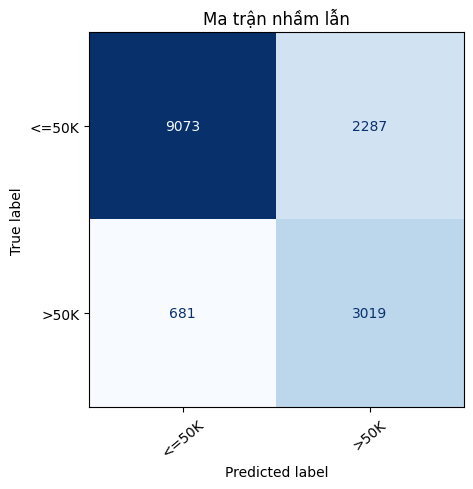

In [1]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'adult'
train = pd.read_csv(get_file('adult.data.csv'), skipinitialspace=True)
test = pd.read_csv(get_file('adult.test.csv'), skipinitialspace=True)
raw_train, raw_test = len(train), len(test)
for df in (train, test):
    df.replace(r'^\s*\?\s*$', np.nan, regex=True, inplace=True)
    for col in df.select_dtypes(include='object'):
        df[col] = df[col].str.strip()
    df['income'] = df['income'].str.rstrip('.')
train = train.dropna().drop(columns=['fnlwgt']).reset_index(drop=True)
test = test.dropna().reset_index(drop=True)
n_train, n_test = len(train), len(test)
data = pd.concat([train, test], ignore_index=True)
print(f'Số mẫu trước xử lý: train={raw_train}, test={raw_test}')
print(f'Số mẫu sau xử lý: train={n_train}, test={n_test}; gộp={len(data)}')

features = data.drop(columns=['income'])
labels = data['income']
print('Dữ liệu thuộc tính:', features.shape, ' | Nhãn:', labels.shape)
print('Phân bố nhãn:')
print(labels.value_counts().to_string())
cat_cols = features.select_dtypes(include=['object', 'category']).columns.tolist()
features_encoded = pd.get_dummies(features, columns=cat_cols, dtype=int)
print('Cột phân loại:', cat_cols)
print('Dạng sau One-Hot Encoding:', features_encoded.shape)
print(features_encoded.head(3).to_string(index=False, max_cols=12))
X_train, X_test = features_encoded.iloc[:n_train], features_encoded.iloc[n_train:]
y_train, y_test = labels.iloc[:n_train], labels.iloc[n_train:]
print('Train:', X_train.shape, 'Test:', X_test.shape)
assert len(X_train) == n_train and len(X_test) == n_test
model = MultinomialNB(alpha=1.0) if DATASET == 'mush' else GaussianNB()
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Naïve Bayes:', type(model).__name__)
print('Accuracy:', round(accuracy_score(y_test, pred), 4))
print('Precision (macro):', round(precision_score(y_test, pred, average='macro', zero_division=0), 4))
print('Recall (macro):', round(recall_score(y_test, pred, average='macro', zero_division=0), 4))
print('F1-score (macro):', round(f1_score(y_test, pred, average='macro', zero_division=0), 4))
print(classification_report(y_test, pred, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues', colorbar=False, xticks_rotation=40)
plt.title('Ma trận nhầm lẫn')
plt.tight_layout(); plt.show()
